## PH24C031

**1st problem -**

In [67]:
X = [1., 2.1, 5.]
Y = [8., 20.6, 13.7]

def linear(X, Y, x):

    def linear_interpolation(x, x0, y0, x1, y1):
       return y0 + (y1 - y0) * (x - x0) / (x1 - x0)

    if X[0] <= x <= X[-1] :
      for i in range(len(X) - 1):
         x0 = X[i]
         y0 = Y[i]

         x1 = X[i+1]
         y1 = Y[i+1]

         if x0 <= x <=x1:
             y = linear_interpolation(x, x0, y0, x1, y1)

      return y

    else:
      return "x is outside the range"

linear(X=X, Y=Y, x=2.1)

20.6

**2nd problem -**

In [69]:
X = [1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9, 3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4.0, 4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8, 4.9, 5.0]

Y = [1.45, 1.50, 1.55, 1.60, 1.65, 1.71, 1.76, 1.82, 1.88, 1.94, 2.00, 2.06, 2.12, 2.18, 2.24, 2.31, 2.37, 2.44, 2.51, 2.58, 2.65, 2.72, 2.79, 2.86, 2.93, 3.01, 3.08, 3.16, 3.24, 3.32, 3.40, 3.48, 3.56, 3.64, 3.72, 3.81, 3.89, 3.98, 4.07, 4.16, 4.25]

linear(X, Y, 1)

1.45

**3rd problem -**

In [71]:
def interpolate(x_list, y_list, x):
    
    n =len(x_list)
    y = 0
    
    for i in range(n):
        p = 1
        for j in range(n):
            if i != j:
                 p *= (x - x_list[j]) / (x_list[i] - x_list[j])
        y += y_list[i] * p
        
    return y

**4th problem -**

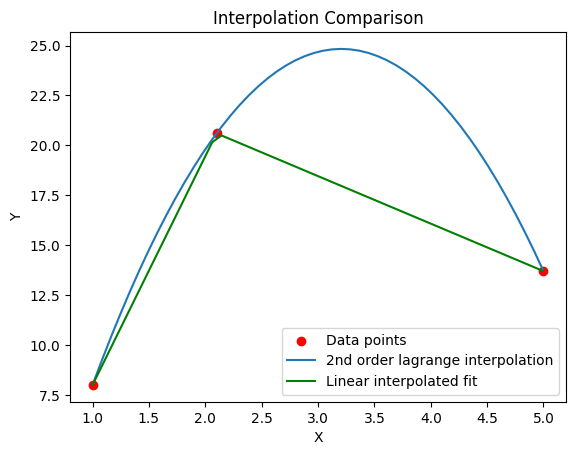

In [73]:
import numpy as np
import matplotlib.pyplot as plt

x_list1 = [1., 2.1, 5.]
y_list1 = [8., 20.6, 13.7]

xplt = np.linspace(x_list1[0], x_list1[-1])
yplt = []
yplt_l = []

for xp in xplt:
  yplt.append(interpolate(x_list1, y_list1, xp))
  yplt_l.append(linear(x_list1, y_list1, xp))

plt.scatter(x_list1, y_list1, label = "Data points", color = 'red')
plt.plot(xplt, yplt, label = "2nd order lagrange interpolation")
plt.plot(xplt, yplt_l, label = "Linear interpolated fit", color = 'green')
plt.title("Interpolation Comparison")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()

**5th problem -**

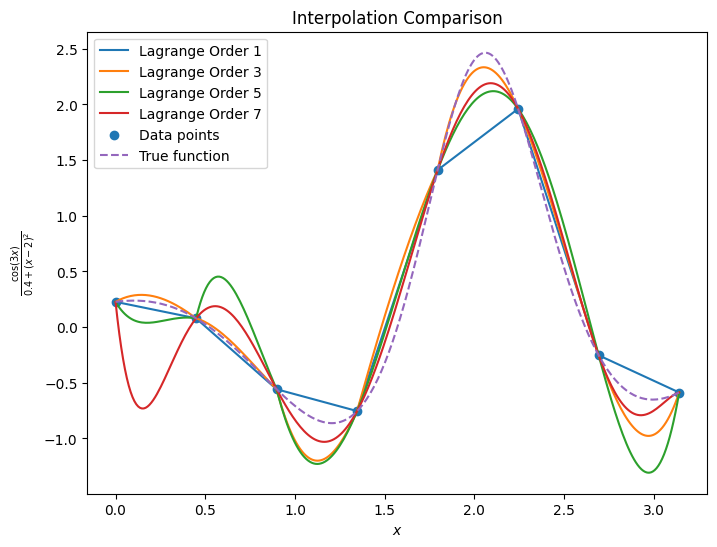

In [61]:
def func(theta):
    return np.cos(3 * theta) / (0.4 + (theta - 2) ** 2)

thet = np.linspace(0, np.pi, 8)
theta = np.linspace(0, np.pi, 300)

orders = [1, 3, 5, 7]

plt.figure(figsize=(8, 6))

for order in orders:
    
    f = np.zeros_like(theta)
    for i in range(len(thet) - order):
        
        subset_x = thet[i:i + order + 1]
        subset_y = func(thet)[i:i + order + 1]
        mask = (theta >= subset_x[0]) & (theta <= subset_x[-1])
        f[mask] = interpolate(subset_x, subset_y, theta[mask])
    plt.plot(theta, f, label=f"Lagrange Order {order}")

plt.scatter(thet, func(thet), label = "Data points")
plt.plot(theta, func(theta), '--', label = "True function")
plt.title("Interpolation Comparison")
plt.xlabel(r'$x$')
plt.ylabel(r'$\frac{\cos(3x)}{0.4 + (x-2)^2}$')
plt.legend()
plt.show()

**6th problem -**

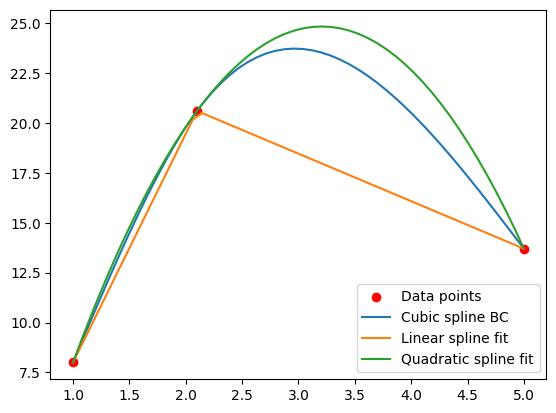

In [35]:
from scipy.interpolate import CubicSpline, interp1d

X = [1., 2.1, 5.]
Y = [8., 20.6, 13.7]

xplt = np.linspace(X[0], X[-1])

yplt = CubicSpline(X, Y, bc_type = "natural")
yplt1 = interp1d(X, Y, kind = "linear")
yplt2 = interp1d(X, Y, kind = "quadratic")

plt.scatter(X, Y, label = "Data points", color = 'red')
plt.plot(xplt, yplt(xplt), label = "Cubic spline BC")
plt.plot(xplt, yplt1(xplt), label = "Linear spline fit")
plt.plot(xplt, yplt2(xplt), label = "Quadratic spline fit")
plt.legend()
plt.show()

**7th problem -**

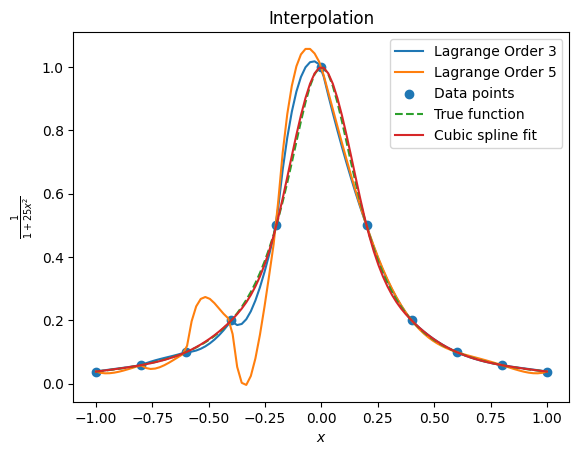

In [65]:
from scipy.interpolate import CubicSpline, interp1d

def func1(x):
  return 1/(1 + 25*(x**2))

xplt = np.linspace(-1, 1, 11)
xn = np.linspace(-1, 1, 100)

y_cubic = CubicSpline(xplt, func1(xplt), bc_type = "natural")

orders = [3, 5]

for order in orders:
    f = np.zeros_like(xn)
    for i in range(len(xplt) - order):
        subset_x = xplt[i:i + order + 1]
        subset_y = func1(xplt)[i:i + order + 1]
        mask = (xn >= subset_x[0]) & (xn <= subset_x[-1])
        f[mask] = interpolate(subset_x, subset_y, xn[mask])
    plt.plot(xn, f, label=f"Lagrange Order {order}")


plt.scatter(xplt, func1(xplt), label = "Data points")
plt.plot(xn, func1(xn),'--', label = "True function")
plt.plot(xn, y_cubic(xn), label = "Cubic spline fit")
plt.title("Interpolation")
plt.xlabel(r'$x$')
plt.ylabel(r'$\frac{1}{1 + 25x^2}$')
plt.legend()
plt.show()